### 1.	Import the dataset: Load the data into your analysis environment.

#### Import libraries

In [4]:
import warnings
warnings.filterwarnings('ignore')

In [109]:
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import researchpy as rp

from scipy.stats import chi2_contingency, levene, ttest_ind, kstest,kruskal

import pingouin as pg

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,RobustScaler


# Enable experimental IterativeImputer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer

import re

import joblib

from sklearn.model_selection import train_test_split

import category_encoders as ce

In [6]:
while True:
    user_input=input("Please enter the path of csv file: ").strip("'\"")
    file_path=Path(user_input)

    try:
        if not file_path.is_file():
            raise FileNotFoundError(f"No file found at: {file_path.absolute()}") # absolute()-exact path

        if file_path.suffix.lower() != ".csv":  # if wrong extension file uploaded
            raise ValueError(f"Wrong file type! Expected .csv, found {file_path.suffix.lower()}")

        # if no error found, read the data
        house=pd.read_csv(file_path)
        print("File loaded successfully")
        print("Shape of dataset: ", house.shape)

        break

    except FileNotFoundError as e:
        print(f"error: {e}")

    except ValueError as e:
        print(f"error: {e}")

    except pd.errors.EmptyDataError:
        print("Error: This file is completely empty")

    except pd.errors.ParseError:
        print("This file is corrupted or formatted incorrectly.")

    except Exception as e: # any other error
        print(f"An unexpected error occured: {e}")


Please enter the path of csv file:  "C:\Users\Owner\Downloads\Data Science Metro\DSPP\Projects\quebec_housing_sales_v2.csv"


File loaded successfully
Shape of dataset:  (5000, 14)


#### Path for quebec_housing_sales_v2.csv
"C:\Users\Owner\Downloads\Data Science Metro\DSPP\Projects\quebec_housing_sales_v2.csv"

#### Kaggle dataset link:
https://www.kaggle.com/datasets/rickyjackson/quebec-housing-sales-price

###  Find the business objective of your project.
##### This dataset contains Quebec residential sale prices from 2021 to 2025, covering 5,000 properties across 32 cities, with details on location (city, neighborhood), property characteristics (property type, bedrooms, bathrooms, living area, lot size, year built, renovation year, garage, basement), and sale information (sale year, sale price).
- **target** is to predict sale price

### 	Perform the necessary analytics to fulfill your objective, including but not limited to the following steps:
#### Display records: Show the first 5 and last 5 records of the dataset. 

In [7]:
pd.options.display.max_columns=500
house.head() # first 5 records

,property_id,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqft,lot_size_sqft,year_built,renovation_year,garage,basement,sale_year,sale_price
0,1,Châteauguay,Centre-Ville,Townhouse,3,2,1160,2304.0,2022,NaN,Yes,No,2024,326000
1,2,Trois-Rivières,Cap-de-la-Madeleine,Duplex,4,4,1807,5869.0,2006,2024.0,No,Yes,2025,444000
2,3,Lévis,Charny,Townhouse,3,1,803,3387.0,1989,NaN,Yes,Yes,2025,273000
3,4,Laval,Fabreville,Single Family,3,3,1083,11417.0,1972,2016.0,Yes,Yes,2023,465000
4,5,Longueuil,Greenfield Park,Condo,2,2,714,NaN,1997,2010.0,Yes,No,2022,371000


In [8]:
house.tail() # last 5 records

,property_id,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqft,lot_size_sqft,year_built,renovation_year,garage,basement,sale_year,sale_price
4995,4996,Sherbrooke,Lennoxville,Single Family,4,4,1411,9036.0,1985,NaN,Yes,No,2023,406000
4996,4997,Rimouski,Rimouski Centre,Single Family,5,2,1432,6474.0,2010,NaN,Yes,No,2022,198000
4997,4998,Montréal,Villeray,Duplex,4,2,1692,6070.0,1953,NaN,Yes,No,2024,680000
4998,4999,Brossard,Secteur B,Bungalow,2,1,954,4686.0,1994,2013.0,Yes,Yes,2024,431000
4999,5000,Terrebonne,Lachenaie,Condo,1,1,861,NaN,1969,2010.0,Yes,No,2021,472000


In [9]:
house.shape

(5000, 14)

In [10]:
house.columns

Index(['property_id', 'city', 'neighborhood', 'property_type', 'bedrooms',
       'bathrooms', 'living_area_sqft', 'lot_size_sqft', 'year_built',
       'renovation_year', 'garage', 'basement', 'sale_year', 'sale_price'],
      dtype='object')

#### Since property_id is just an id of the house with all unique values so drop this column

In [11]:
house.drop(columns=['property_id'], inplace=True)
house.shape

(5000, 13)

#### -	Identify data types: Check and note the data types for each variable. 

In [12]:
house.shape

(5000, 13)

In [13]:
house.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   city              5000 non-null   object 
 1   neighborhood      5000 non-null   object 
 2   property_type     5000 non-null   object 
 3   bedrooms          5000 non-null   int64  
 4   bathrooms         5000 non-null   int64  
 5   living_area_sqft  5000 non-null   int64  
 6   lot_size_sqft     3789 non-null   float64
 7   year_built        5000 non-null   int64  
 8   renovation_year   1592 non-null   float64
 9   garage            5000 non-null   object 
 10  basement          5000 non-null   object 
 11  sale_year         5000 non-null   int64  
 12  sale_price        5000 non-null   int64  
dtypes: float64(2), int64(6), object(5)
memory usage: 507.9+ KB


#### Check Levels of Variables
- Below is the display of number of levels for each variable in the dataset, alongwith datatype of each column.

In [14]:
for i in range(len(house.columns)):
    print("*"*50)
    print("-"*10, house.columns[i], ",levels: ", house.iloc[:,i].nunique(), ", Column dtype: ", house[house.columns[i]].dtypes, "-"*10)
    print(house.iloc[:, i].value_counts())
    print()

**************************************************
---------- city ,levels:  32 , Column dtype:  object ----------
city
Montréal                      919
Québec                        529
Laval                         460
Longueuil                     394
Brossard                      244
Sherbrooke                    220
Gatineau                      207
Terrebonne                    174
Repentigny                    147
Trois-Rivières                137
Lévis                         124
Saint-Jean-sur-Richelieu      121
Saint-Jérôme                  117
Blainville                    112
Saguenay                       93
Mirabel                        90
Granby                         90
Drummondville                  89
Dollard-des-Ormeaux            82
Châteauguay                    81
Vaudreuil-Dorion               79
Boucherville                   72
Saint-Bruno-de-Montarville     57
Victoriaville                  56
Candiac                        55
Pointe-Claire                 

#### A check on missing values

In [15]:
def information(df):
    df_information=pd.concat([df.dtypes, df.nunique(), df.isnull().sum()],\
                            keys=['Data Types', 'Number of Unique Values', 'Number of Missing Values'],\
                             axis=1)
    return df_information

In [16]:
information(house)

,Data Types,Number of Unique Values,Number of Missing Values
city,object,32,0
neighborhood,object,72,0
property_type,object,6,0
bedrooms,int64,8,0
bathrooms,int64,6,0
living_area_sqft,int64,1670,0
lot_size_sqft,float64,3144,1211
year_built,int64,124,0
renovation_year,float64,21,3408
garage,object,2,0


#### -	Missing entries: Determine the number of missing entries per variable and handle them. 

In [17]:
house.isnull().sum().sort_values(ascending=False)

renovation_year     3408
lot_size_sqft       1211
property_type          0
neighborhood           0
city                   0
bathrooms              0
bedrooms               0
living_area_sqft       0
year_built             0
garage                 0
basement               0
sale_year              0
sale_price             0
dtype: int64

#### Since the percentage of missing values is 4619/(5000*14)=4619/70000=0.06 * 100=6%, so we can either:
- **drop the missing values**
- **fill with median and mode for respective columns**
- **Here, option 2 is used**

In [18]:
house.isnull().sum().sum() # total missing values in the dataset

np.int64(4619)

In [19]:
house.shape

(5000, 13)

In [20]:
#calculatin no. of missing values for each column and it's percentage

def percentage_of_miss(df):
    df1= df[df.columns[df.isnull().sum()>=1]] # dataframe containing all missing values
    total_miss=df1.isnull().sum().sort_values(ascending=False)
    percent_miss=((df1.isnull().sum()/df1.shape[0])*100).sort_values(ascending=False)
    missing_data=pd.concat([total_miss, percent_miss],axis=1,keys=['Number of Missing', 'Percentage of  Miss'])
    return missing_data

In [21]:
percentage_of_miss(house)

,Number of Missing,Percentage of Miss
renovation_year,3408,68.16
lot_size_sqft,1211,24.22


In [22]:
rp.summary_cat(house.isna())

,Variable,Outcome,Count,Percent
0,city,False,5000,100.00
1,neighborhood,False,5000,100.00
2,property_type,False,5000,100.00
3,bedrooms,False,5000,100.00
4,bathrooms,False,5000,100.00
5,living_area_sqft,False,5000,100.00
6,lot_size_sqft,False,3789,75.78
7,,True,1211,24.22
8,year_built,False,5000,100.00
9,renovation_year,True,3408,68.16


#### Get an idea about our data before data prepration
#### Descrptive Statistic of numerical columns

In [23]:
house.describe().T

,count,mean,std,min,25%,50%,75%,max
bedrooms,5000.0,3.488200,1.357435,1.0,2.0,3.0,4.0,8.0
bathrooms,5000.0,2.325800,0.968009,1.0,2.0,2.0,3.0,6.0
living_area_sqft,5000.0,1313.693800,472.106052,469.0,915.0,1273.0,1650.0,2967.0
lot_size_sqft,3789.0,6257.154658,2811.434500,1570.0,4086.0,5767.0,8005.0,14834.0
year_built,5000.0,1983.074000,26.483028,1900.0,1966.0,1985.0,2004.0,2023.0
renovation_year,1592.0,2015.054020,5.764461,2005.0,2010.0,2015.0,2020.0,2025.0
sale_year,5000.0,2023.411600,1.332119,2021.0,2022.0,2024.0,2025.0,2025.0
sale_price,5000.0,480214.000000,177125.385206,114000.0,352750.0,453000.0,584000.0,1425000.0


#### For numerical columns, 
- **renovation_year** has 68% of the data missing so fill NaN with 0 as no information is available
- **lot_size_sqft** has 24% of missing data so fill with median

In [24]:
house=house.fillna({'renovation_year': 0,
             'lot_size_sqft': house.lot_size_sqft.median()})

house.isnull().sum()

city                0
neighborhood        0
property_type       0
bedrooms            0
bathrooms           0
living_area_sqft    0
lot_size_sqft       0
year_built          0
renovation_year     0
garage              0
basement            0
sale_year           0
sale_price          0
dtype: int64

#### -	Duplicate records: Identify and count any duplicate records and handle them. 

In [25]:
house.duplicated().sum()

np.int64(0)

#### In case if duplicated rows are present: use the following strategy

In [26]:
# create a copy of the dataset for future reference
house_original=house.copy()
house_original.shape

(5000, 13)

In [27]:
house[house.duplicated()]

,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqft,lot_size_sqft,year_built,renovation_year,garage,basement,sale_year,sale_price


In [28]:
# In case of dulpicates, save duplicates separately
dup_house=house[house.duplicated()]
dup_house

,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqft,lot_size_sqft,year_built,renovation_year,garage,basement,sale_year,sale_price


In [29]:
# Since duplicates are saved separately, now delete them from the dataset
house.drop_duplicates(inplace=True)
print('original records',house_original.shape,'\nafter dropping duplicates:',house.shape)

original records (5000, 13) 
after dropping duplicates: (5000, 13)


### Univariate analysis: Conduct this analysis on all variables, creating appropriate visualizations.


#### Univariate analysis: Numerical Variables

#### Define numerical columns 

In [30]:
numerical_cols=house.select_dtypes(include='number')
numerical_cols.head()

,bedrooms,bathrooms,living_area_sqft,lot_size_sqft,year_built,renovation_year,sale_year,sale_price
0,3,2,1160,2304.0,2022,0.0,2024,326000
1,4,4,1807,5869.0,2006,2024.0,2025,444000
2,3,1,803,3387.0,1989,0.0,2025,273000
3,3,3,1083,11417.0,1972,2016.0,2023,465000
4,2,2,714,5767.0,1997,2010.0,2022,371000


In [31]:
numerical_cols.shape

(5000, 8)

In [32]:
pd.options.display.max_columns=100
numerical_cols.describe().T

,count,mean,std,min,25%,50%,75%,max
bedrooms,5000.0,3.4882,1.357435,1.0,2.0,3.0,4.0,8.0
bathrooms,5000.0,2.3258,0.968009,1.0,2.0,2.0,3.0,6.0
living_area_sqft,5000.0,1313.6938,472.106052,469.0,915.0,1273.0,1650.0,2967.0
lot_size_sqft,5000.0,6138.4392,2456.317749,1570.0,4628.0,5767.0,7096.0,14834.0
year_built,5000.0,1983.0740,26.483028,1900.0,1966.0,1985.0,2004.0,2023.0
renovation_year,5000.0,641.5932,938.823718,0.0,0.0,0.0,2009.0,2025.0
sale_year,5000.0,2023.4116,1.332119,2021.0,2022.0,2024.0,2025.0,2025.0
sale_price,5000.0,480214.0000,177125.385206,114000.0,352750.0,453000.0,584000.0,1425000.0


#### Plot numerical columns

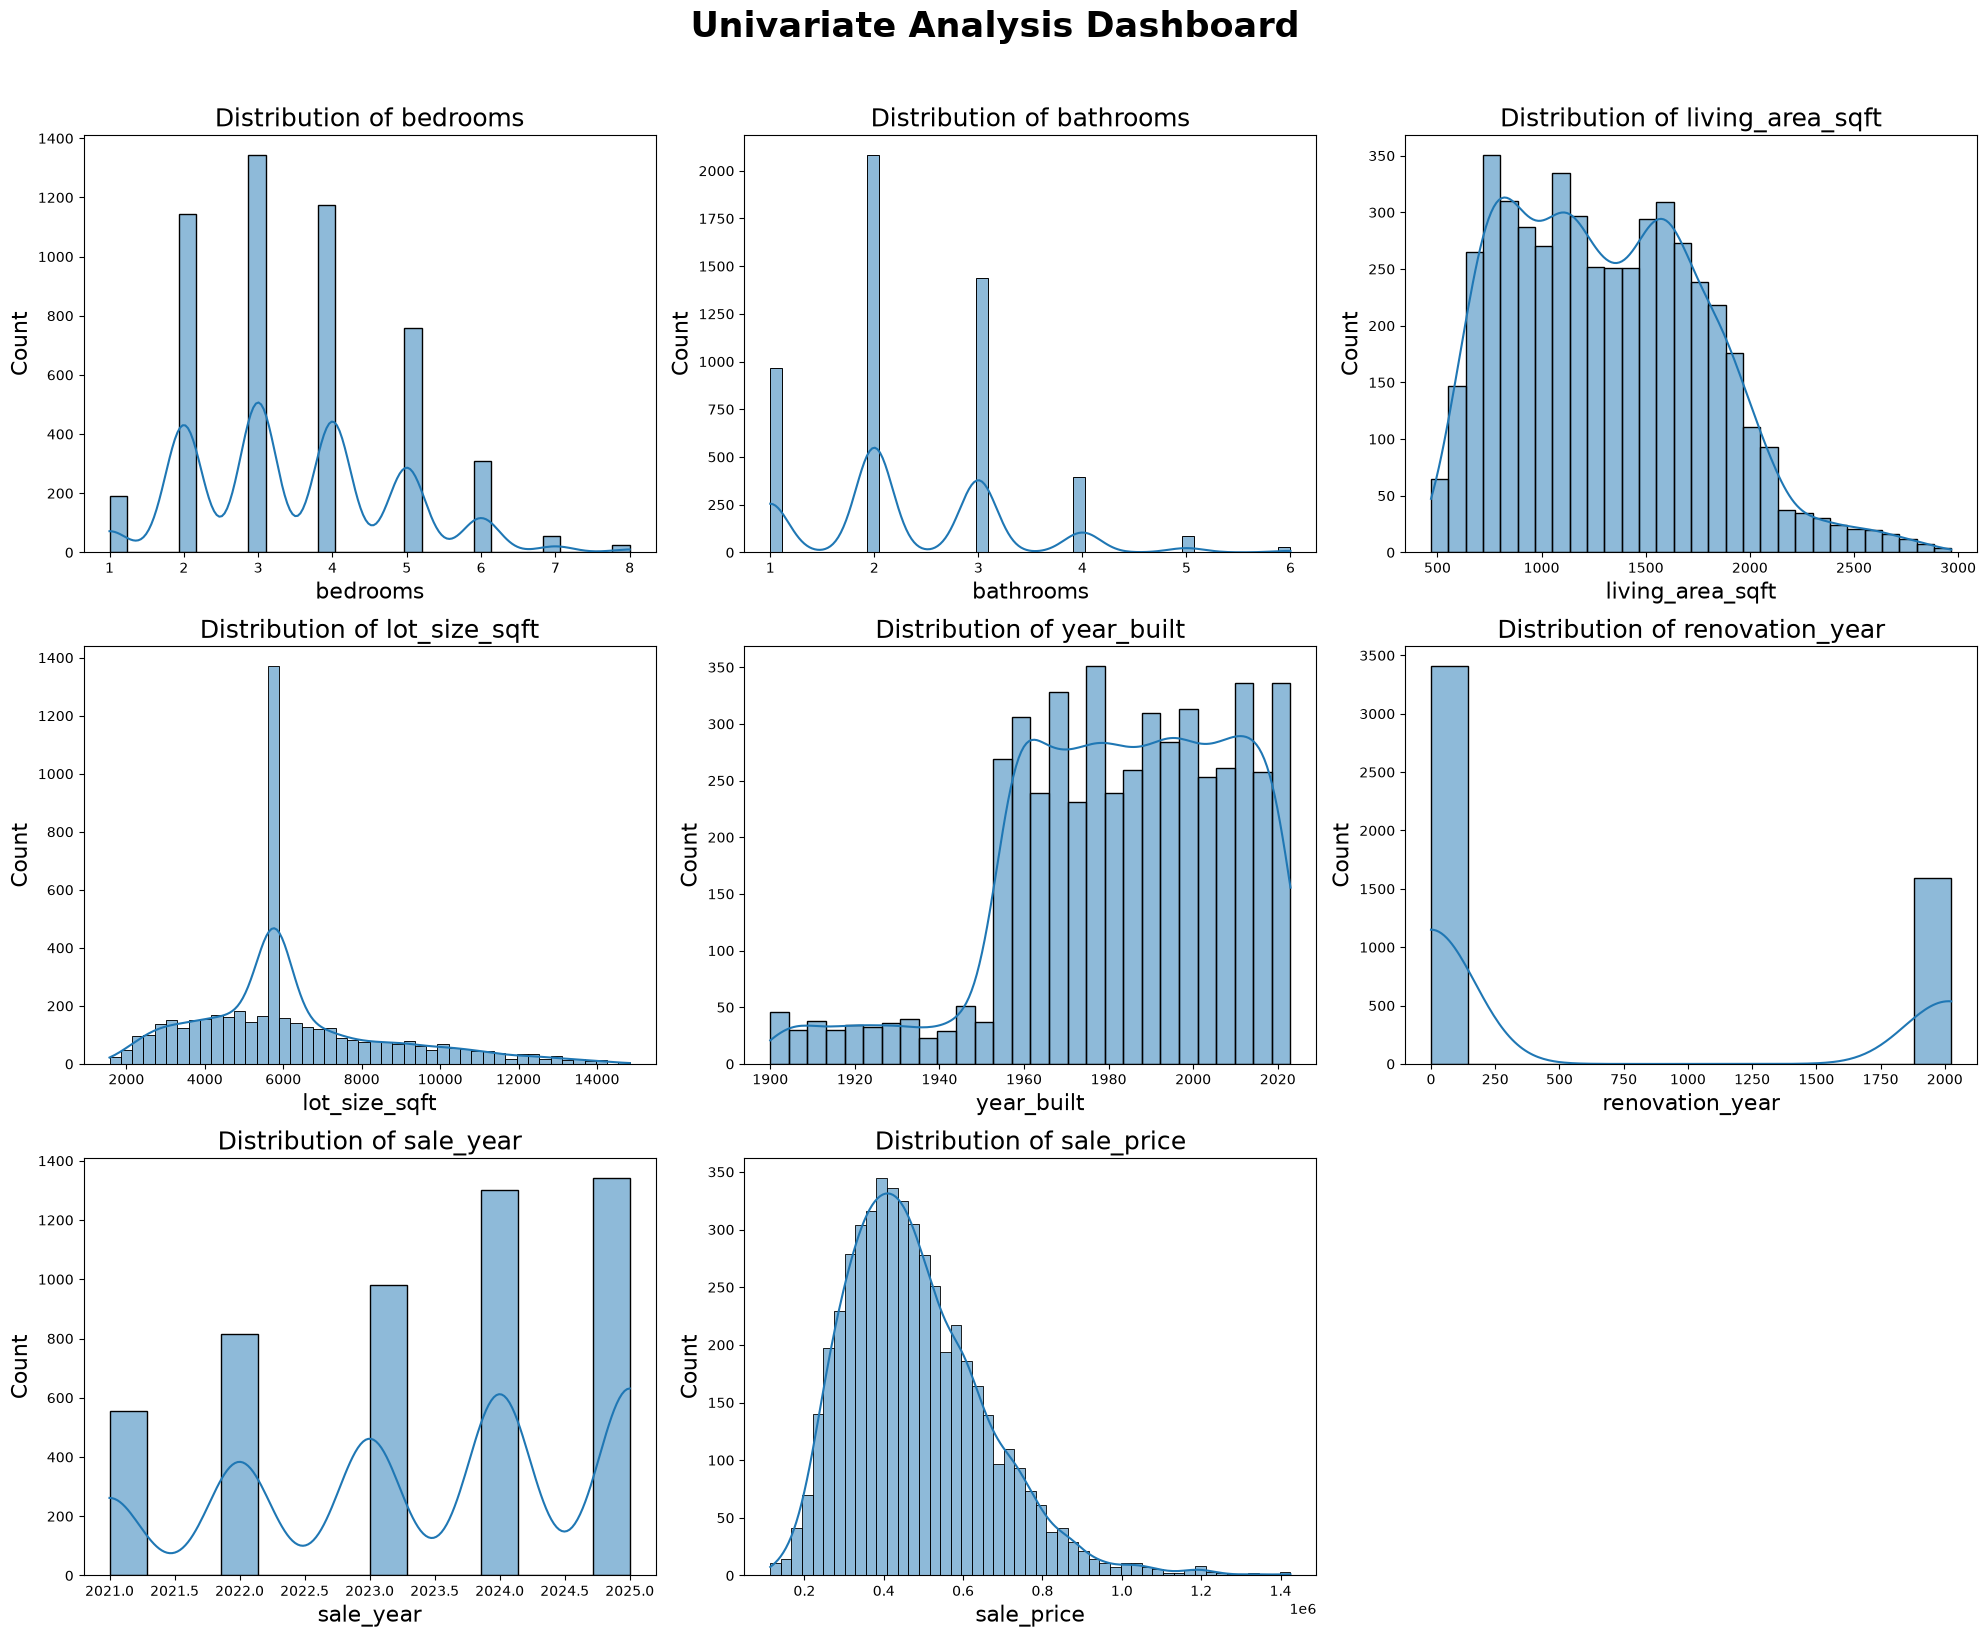

In [33]:
fig, axes=plt.subplots(3,3, figsize=(20,16))
axes=axes.flatten()


for i, var in enumerate(numerical_cols):
    sns.histplot(data=numerical_cols, x=var, kde=True, ax=axes[i])
    axes[i].set_title(f"Distribution of {var}", fontsize=18)
    axes[i].set_xlabel(f"{var}", fontsize=16)
    axes[i].set_ylabel("Count", fontsize=16)

for j in range(len(numerical_cols.columns),len(axes)):
     fig.delaxes(axes[j])
    
plt.suptitle("Univariate Analysis Dashboard", fontsize=25, weight='bold',y=1.02)
plt.tight_layout()
plt.show()

## Descriptive Analysis of Key Features
- Bedrooms: Most of the properties have 3, 4 or 5 bedrooms.
- Bathrooms: Most of the properties have 2 or 3 bathrooms.
- Living_area_sqft: Most homes are between 750 and 1800 sqft, with a few properties over 2000 sqft.
- lot_size_sqft: A majority of the houses have lot size of 6000 sqft with a few properties over 14000 sqft.
- year_built: Construction was low before 1950, after 1950, it is consistent.
- renovation_year: Since this column had missing values that were filled with 0, so the distribution shows a peak at zero then a peak for the year 2000.
- sale_year: Sales are tracked from 2021 to 2025. Trend is upward meaning highest sales in 2025.
- sale_price: It shows a right skewed continuous distribution. Price is scaled in millions. Majority of the houses price between $300,000 and $600,000.

In [34]:
numerical_cols.skew().sort_values(ascending=False)

sale_price          0.978991
lot_size_sqft       0.919628
renovation_year     0.779913
bathrooms           0.667978
living_area_sqft    0.450176
bedrooms            0.443272
sale_year          -0.383366
year_built         -0.707988
dtype: float64

#### Define categorical columns

In [35]:
categorical_cols=house.select_dtypes(include='object')
categorical_cols.head()

,city,neighborhood,property_type,garage,basement
0,Châteauguay,Centre-Ville,Townhouse,Yes,No
1,Trois-Rivières,Cap-de-la-Madeleine,Duplex,No,Yes
2,Lévis,Charny,Townhouse,Yes,Yes
3,Laval,Fabreville,Single Family,Yes,Yes
4,Longueuil,Greenfield Park,Condo,Yes,No


In [36]:
categorical_cols.shape

(5000, 5)

#### Plot categorical columns

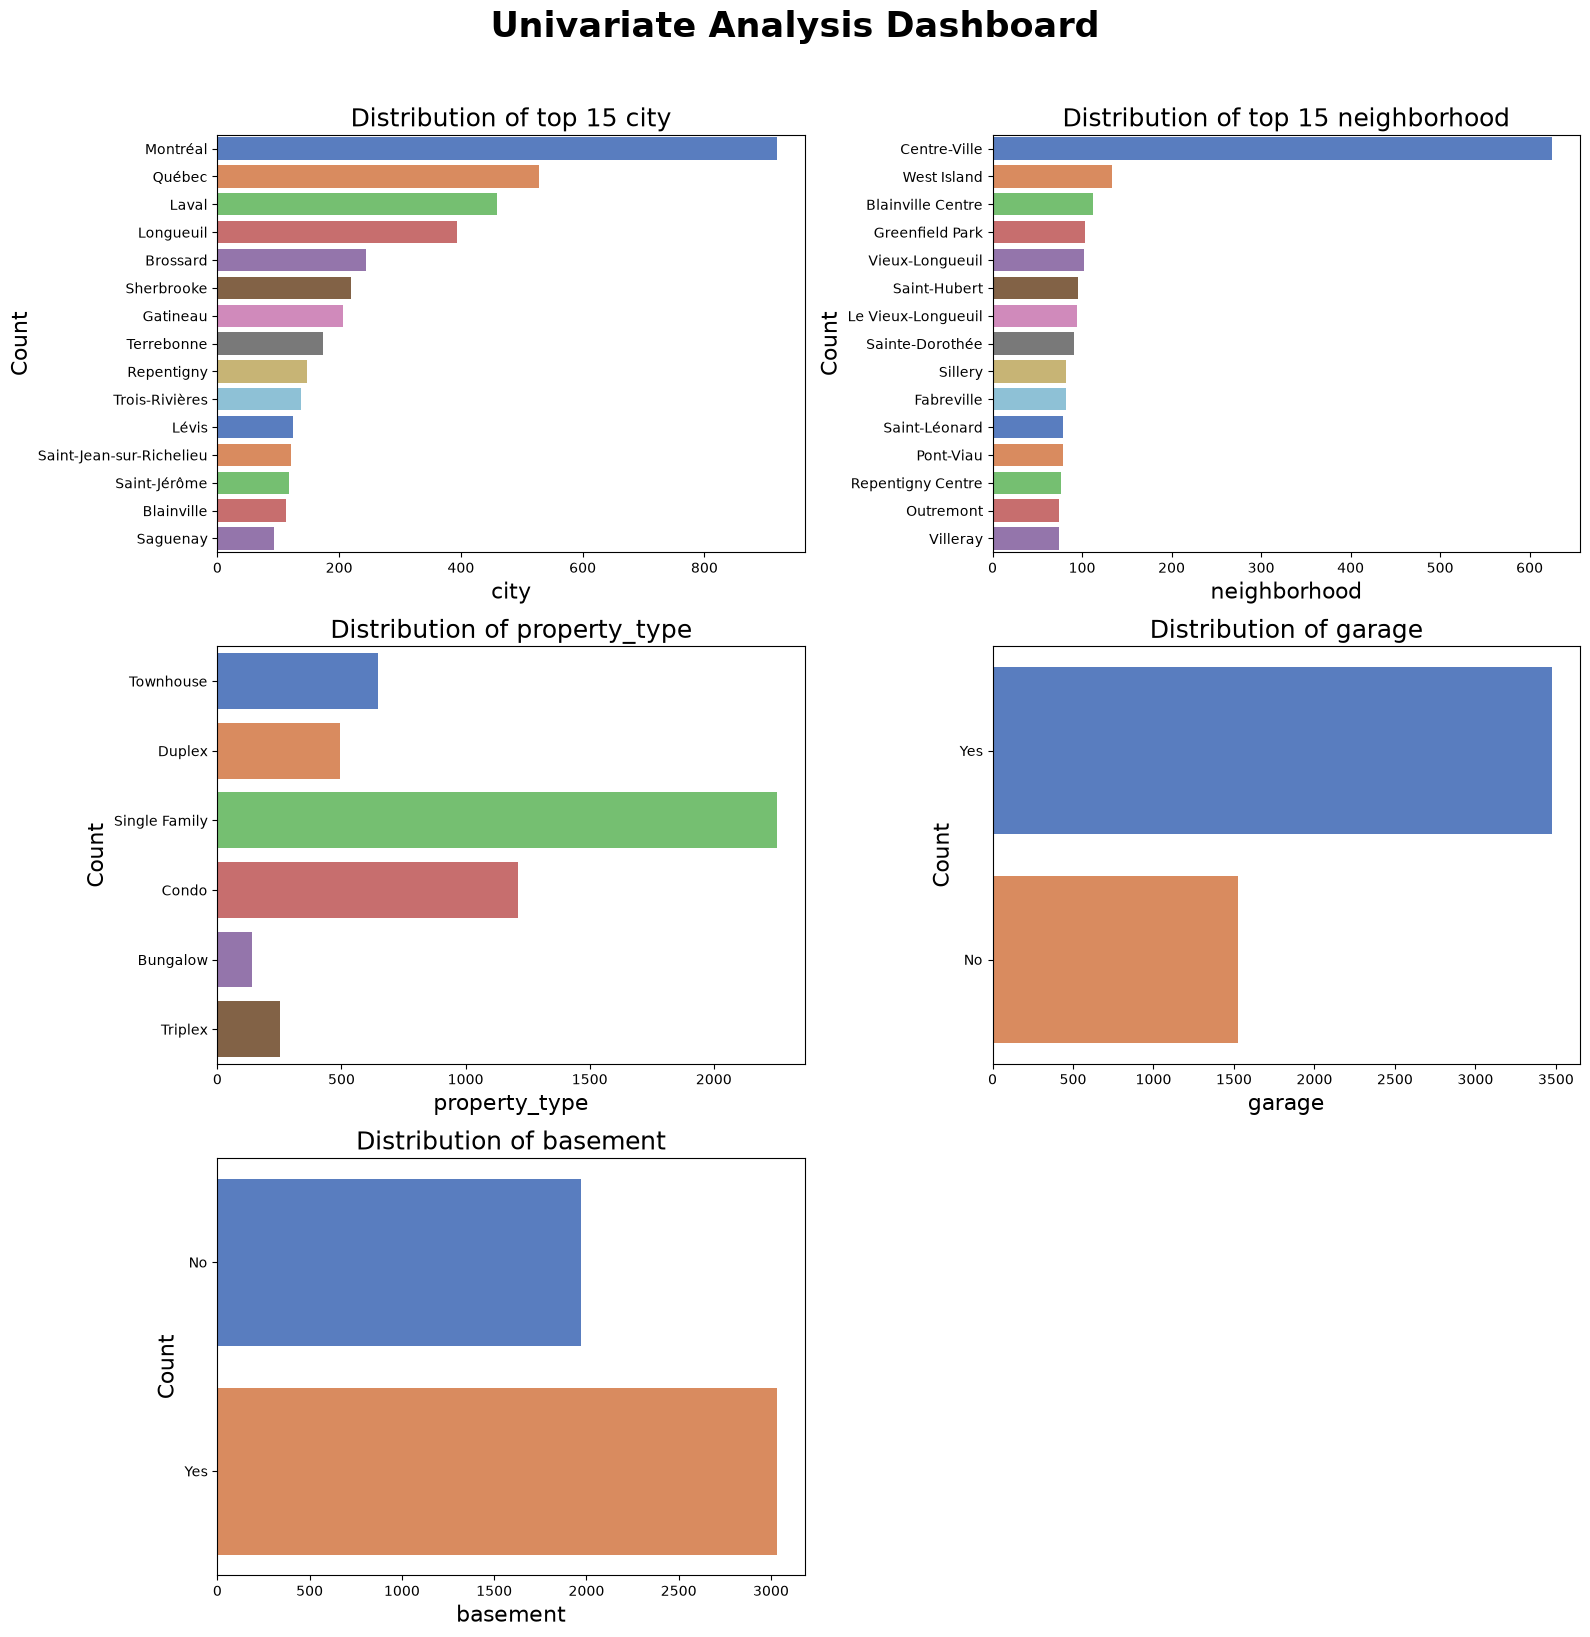

In [37]:
fig, axes= plt.subplots(3,2, figsize=(16,16))
axes=axes.flatten()

for i, var in enumerate(categorical_cols):

    # Check if column has more than 15 levels, store it
    if categorical_cols[var].nunique()>15:
        top_15=categorical_cols[var].value_counts().index[:15]
        
        sns.countplot(data=categorical_cols, y=var, ax=axes[i], order=top_15, \
                      palette='muted')
        
        axes[i].set_title(f"Distribution of top 15 {var}", fontsize=18)
        axes[i].set_xlabel(f"{var}", fontsize=16)
        axes[i].set_ylabel("Count", fontsize=16)

    else:
        sns.countplot(data=categorical_cols, y=var, ax=axes[i],  palette='muted')
        
        axes[i].set_title(f"Distribution of {var}", fontsize=18)
        axes[i].set_xlabel(f"{var}", fontsize=16)
        axes[i].set_ylabel("Count", fontsize=16)

for j in range(len(categorical_cols.columns), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Univariate Analysis Dashboard", fontsize=25, weight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Analysis of Demographics and property'
- top 15 city: Most of the houses in the dataset are from Montreal.
- Top 15 neighborhood: Centre-Ville (Downtown) has most of the houses in the dataset.
- Property_type: Single family houses dominate the market with more than 2000 listings. Condo properties are listed the second most in the market.
- Garage: Around 3500 listings have garage in the property.
- Basement: Around 3000 properties have basement in the house.


### Outlier detection: Use the Tukey method to identify outliers.

In [38]:
# Extreme Tukey method
#lower outer fence: Q1 - 3*IQR
#upper outer fence: Q3 + 3*IQR
def outlier_analysis_Tukey(df,col):
    """
    in this function, distribution( visulization as well as summerization) of only outliers is shown.
    Extreme tukey method is selected
    
    """
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)
    IQR=Q3-Q1
    UOF=Q3+3*(IQR)#UOF is upper outer fence
    LOF=Q1-3*(IQR)#LIF is lower outer fence
    df_out =df[(df[col]<LOF) | (df[col]>UOF)] # I created a new data set that has just include potential outliers
    sns.distplot(df[col])
    return df_out[col] .describe()

In [39]:
numerical_cols.columns

Index(['bedrooms', 'bathrooms', 'living_area_sqft', 'lot_size_sqft',
       'year_built', 'renovation_year', 'sale_year', 'sale_price'],
      dtype='object')

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: bedrooms, dtype: float64

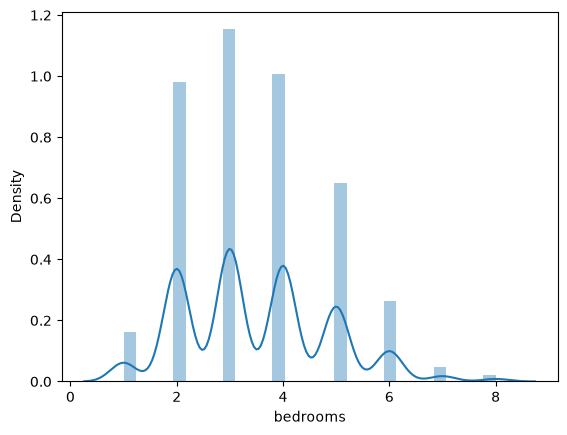

In [40]:
outlier_analysis_Tukey(house,'bedrooms')

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: bathrooms, dtype: float64

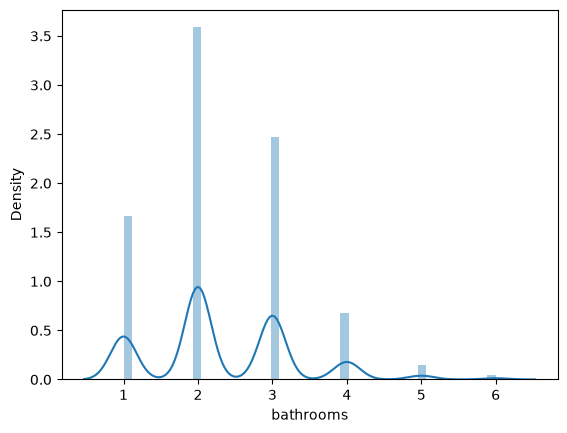

In [41]:
outlier_analysis_Tukey(house,'bathrooms')

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: living_area_sqft, dtype: float64

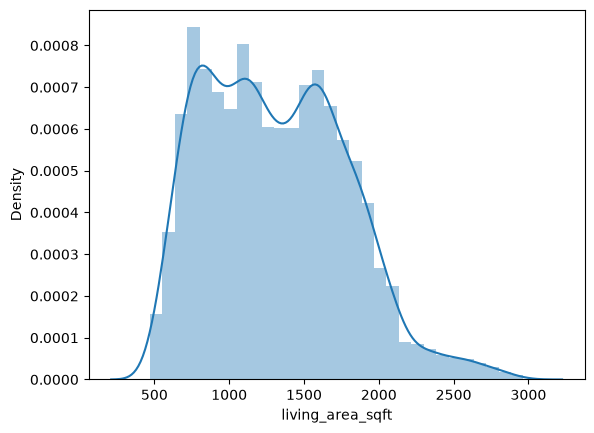

In [42]:
outlier_analysis_Tukey(house,'living_area_sqft')

count        7.000000
mean     14725.428571
std         92.500193
min      14562.000000
25%      14685.500000
50%      14741.000000
75%      14785.000000
max      14834.000000
Name: lot_size_sqft, dtype: float64

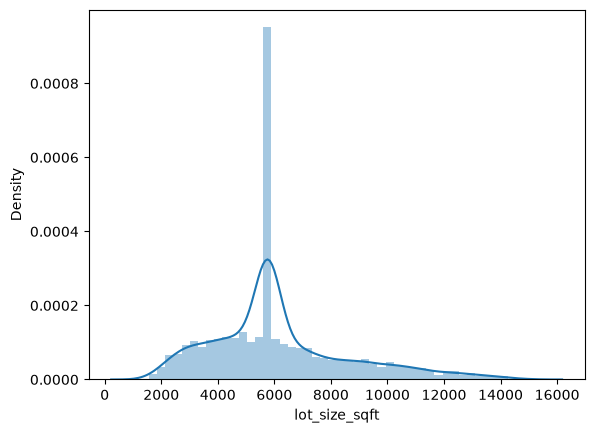

In [43]:
outlier_analysis_Tukey(house,'lot_size_sqft')

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: year_built, dtype: float64

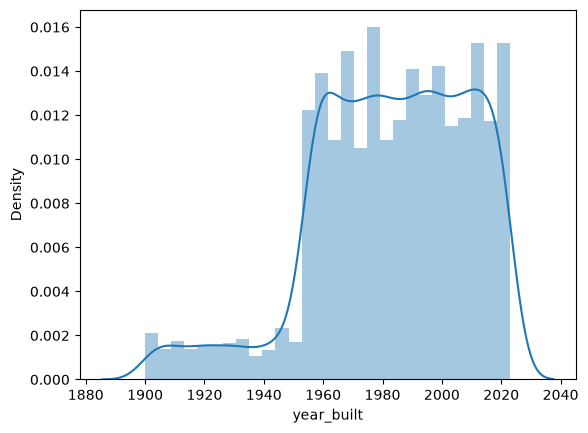

In [44]:
outlier_analysis_Tukey(house,'year_built')

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: renovation_year, dtype: float64

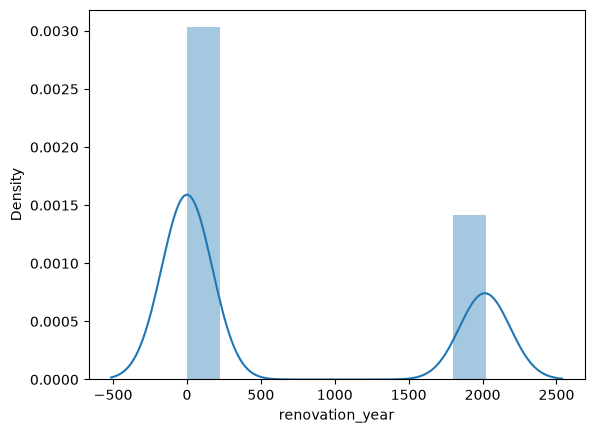

In [45]:
outlier_analysis_Tukey(house,'renovation_year')

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: sale_year, dtype: float64

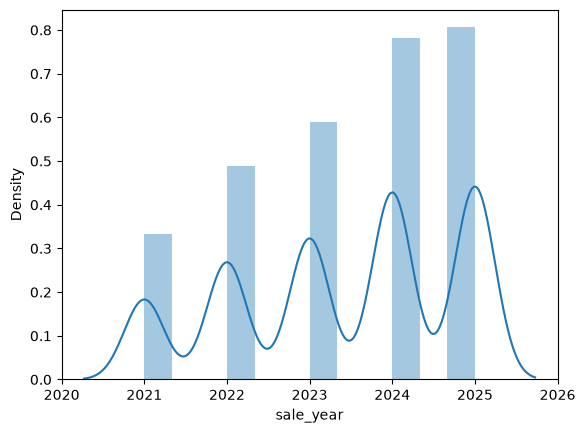

In [46]:
outlier_analysis_Tukey(house,'sale_year')

count    6.000000e+00
mean     1.377000e+06
std      4.648871e+04
min      1.318000e+06
25%      1.343250e+06
50%      1.380000e+06
75%      1.416000e+06
max      1.425000e+06
Name: sale_price, dtype: float64

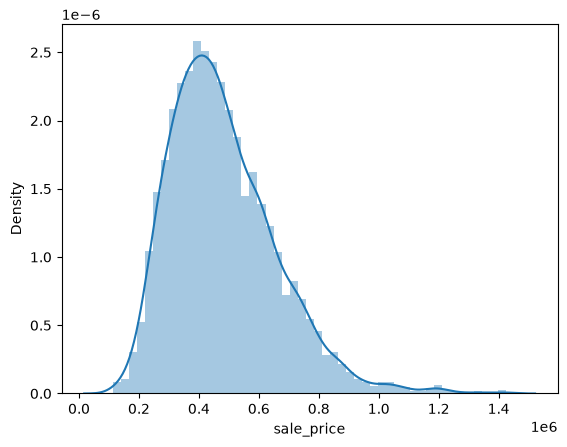

In [47]:
outlier_analysis_Tukey(house,'sale_price')

### -	Bivariate analysis: Perform at least one analysis for each of the following hypothesis tests:
#### - Chi-square test to assess independence between two categorical variables.


In [48]:
categorical_cols.columns

Index(['city', 'neighborhood', 'property_type', 'garage', 'basement'], dtype='object')

#### Association between 'basement' and 'property_type'

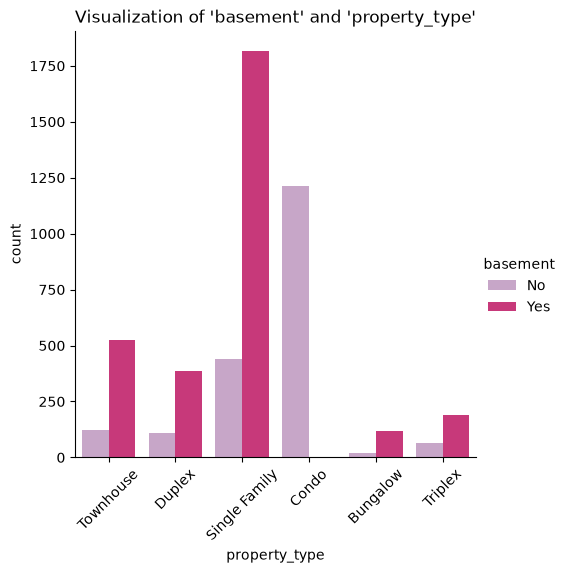

In [49]:
sns.catplot(x='property_type', data=categorical_cols, kind='count', hue='basement', palette='PuRd')

plt.xticks(rotation=45)
plt.title("Visualization of 'basement' and 'property_type'")
plt.show()

## Analysis:
Majority of the single family homes have the basement. Condo properties , of course, have no basement. A few Bungalow do not have basement.


In [50]:
contingency_table1 = pd.crosstab(categorical_cols['basement'],categorical_cols['property_type'],margins = True)
contingency_table1

property_type,Bungalow,Condo,Duplex,Single Family,Townhouse,Triplex,All
basement,,,,,,,
No,21,1211,108,439,124,65,1968
Yes,118,0,385,1815,525,189,3032
All,139,1211,493,2254,649,254,5000


#### Chi-squared test of independence
##### The Null and Alternate Hypotheses


- H0:There is no statistically significant relationship between basement and property_type.

- Ha:There is a statistically significant relationship between basement and property_type.

##### Assumption:
The Chi-square test statistic can be used if the following conditions are satisfied:

1. N, the total frequency, should be reasonably large, say greater than 50.

2. The sample observations should be independent. This implies that no individual item should be included twice or more in the sample.
   
3. No expected frequencies should be small. Small is a relative term. Preferably each expected frequencies should be larger than 10 but in any case not less than 5.

In [51]:
def chi_square(df,c1,c2):
    chi_2, p_val, dof, exp_val = chi2_contingency(pd.crosstab(df[c1],df[c2],margins = False))# make sure margins = False
    print("Actual values:\n")
    print(pd.crosstab(df[c1],df[c2],margins = False))
    print("="*100)
    print("Expected values: \n")
    print(exp_val)
    print("="*100)
    
    #print('\nChi-square is : %f'%chi_2, '\n\np_value is : %f'%p_val, '\n\ndegree of freedom is : %i'%dof)
    print(f'\nChi-square is : {chi_2}', f'\n\np_value is : {p_val}', f'\n\ndegree of freedom is :{dof}')
    print("="*100)
    if exp_val.min()<5 or np.sum(exp_val)<50 : print("\n********************************************\nWarning :We have some small expected \
values or the total number of observations is not enough to get any conclusion\n******************************************** ")
        #Note for sum of all values in dataframe use df.values.sum() and for numpy.ndarray use np.sum(arr)
    elif p_val < 0.05:# consider significan level is 5%
        print(F"\nThere is statistiacally significant correlation between {c1} and {c2} at 0.05 significant level")
    else:
        print(F"\nThere is no correlation between the two variables( we don't have enough evidence to conclude there is a a statistically significant relationship between {c1} and {c2}")        

In [52]:
chi_square(categorical_cols,'basement', 'property_type')

Actual values:

property_type  Bungalow  Condo  Duplex  Single Family  Townhouse  Triplex
basement                                                                 
No                   21   1211     108            439        124       65
Yes                 118      0     385           1815        525      189
Expected values: 

[[  54.7104  476.6496  194.0448  887.1744  255.4464   99.9744]
 [  84.2896  734.3504  298.9552 1366.8256  393.5536  154.0256]]

Chi-square is : 2467.9777393112377 

p_value is : 0.0 

degree of freedom is :5

There is statistiacally significant correlation between basement and property_type at 0.05 significant level


#### Cramer's V

In [53]:
def cramers_V(var1,var2) :
  crosstab =np.array(pd.crosstab(var1,var2, rownames=None, colnames=None)) # Cross table building
  stat = chi2_contingency(crosstab)[0] # Keeping of the test statistic of the Chi2 test
  obs = np.sum(crosstab) # Number of observations
  mini = min(crosstab.shape)-1 # Take the minimum value between the columns and the rows of the cross table
  return np.sqrt((stat/(obs*mini)))

In [54]:
cramers_V(categorical_cols['basement'],categorical_cols['property_type'])

np.float64(0.702563554322488)

In [55]:
rows=[]

for var1 in categorical_cols.columns:
    col=[]
    for var2 in categorical_cols.columns:
        cramers=cramers_V(categorical_cols[var1], categorical_cols[var2]) # apply Cramer's V test
        col.append(round(cramers,2)) # append the values onto columns of dataframe
    rows.append(col)

cramers=np.array(rows)
df_cramers=pd.DataFrame(cramers, columns=categorical_cols.columns, index=categorical_cols.columns)

In [56]:
df_cramers

,city,neighborhood,property_type,garage,basement
city,1.00,0.87,0.08,0.19,0.08
neighborhood,0.87,1.00,0.12,0.21,0.12
property_type,0.08,0.12,1.00,0.18,0.70
garage,0.19,0.21,0.18,1.00,0.12
basement,0.08,0.12,0.70,0.12,1.00


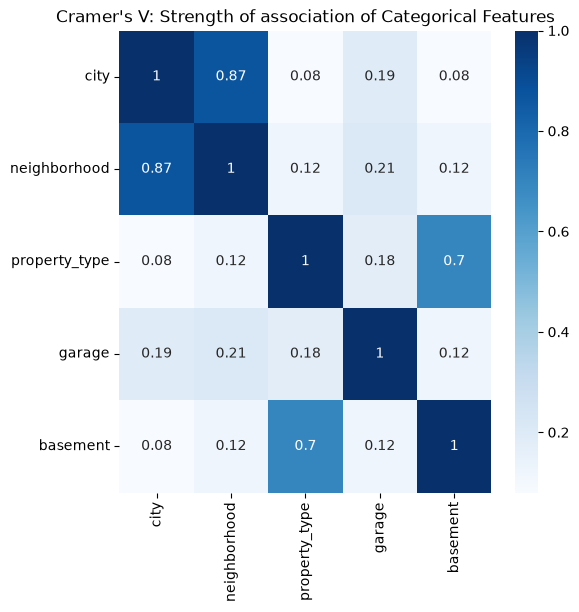

In [57]:
plt.figure(figsize=(6,6))

sns.heatmap(df_cramers, cmap='Blues', annot=True)
plt.title("Cramer's V: Strength of association of Categorical Features")

plt.show()

## Analysis:
To validate these findings, Chi-Square test of Independence was conducted that showed a statistically significant association between ‘basement’ and ‘property_type’ and the strength of association calculated by Cramer’s V is 0.7 that means basement and property_type are strongly associated. The image above visualizes the findings of Chi-Square and Cramer’s V.

## Correlation analysis to examine relationships between two numeric variables.

In [58]:
corr = numerical_cols.corr()
corr.style.background_gradient(cmap='coolwarm')
# 'RdBu_r', 'BrBG_r', & PuOr_r are other good diverging colormaps

,bedrooms,bathrooms,living_area_sqft,lot_size_sqft,year_built,renovation_year,sale_year,sale_price
bedrooms,1.000000,0.550901,0.679949,0.132607,0.003931,0.001210,-0.013907,0.466240
bathrooms,0.550901,1.000000,0.622967,0.063543,0.006722,-0.014105,0.023968,0.457287
living_area_sqft,0.679949,0.622967,1.000000,0.165391,-0.004746,0.002277,0.007373,0.631798
lot_size_sqft,0.132607,0.063543,0.165391,1.000000,-0.009273,-0.000210,-0.008695,0.183164
year_built,0.003931,0.006722,-0.004746,-0.009273,1.000000,-0.212347,0.007404,0.058479
renovation_year,0.001210,-0.014105,0.002277,-0.000210,-0.212347,1.000000,0.019137,0.060640
sale_year,-0.013907,0.023968,0.007373,-0.008695,0.007404,0.019137,1.000000,0.284728
sale_price,0.466240,0.457287,0.631798,0.183164,0.058479,0.060640,0.284728,1.000000


## Analysis:
- living_area_sqft is the strongest predictor of sale_price.
- Bedrooms & bathrooms show moderate positive correlation with sale_price and with each other as well.
- Year_built & sale_year show either negative or a very weak positive correlation with other features.


#### 	T-test or similar test to compare means/median between two groups.
#### Categorical vs Continuous: Summarization

In [59]:
house.dtypes

city                 object
neighborhood         object
property_type        object
bedrooms              int64
bathrooms             int64
living_area_sqft      int64
lot_size_sqft       float64
year_built            int64
renovation_year     float64
garage               object
basement             object
sale_year             int64
sale_price            int64
dtype: object

In [60]:
house['basement'].value_counts()

basement
Yes    3032
No     1968
Name: count, dtype: int64

In [61]:
house.groupby('basement').agg({'living_area_sqft':'mean'})

,living_area_sqft
basement,
No,1041.255081
Yes,1490.527375


#### Visulization: grouped boxplot

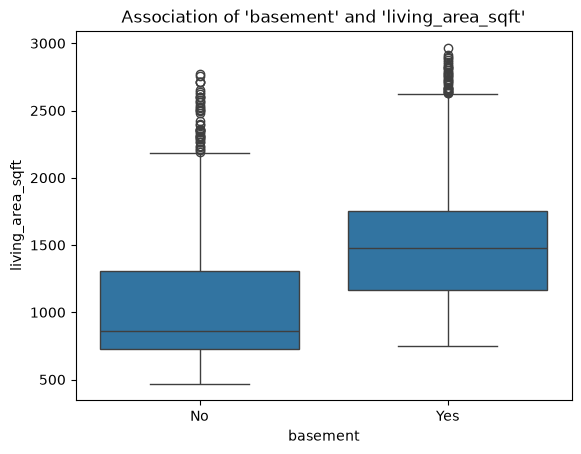

In [62]:
sns.boxplot(data=house, x='basement', y='living_area_sqft')
plt.title("Association of 'basement' and 'living_area_sqft'")
plt.show()

## Analysis:
- **Homes with basement** have a larger iving_area_sqft, median area of these houses is around 1500 sqft. There are outliers in both the distributions. House without basement have larger properties above 2200sqft to 2800sqft.
- **Homes without basement** have smaller living area in sqft from 750 to 1300sqft, with median around 800sqft. Houses with basement have outliers starting from 2600sqft to 2900sqft.


#### 'basement' has two levels, divide them into two dataframe

In [63]:
base=house[house['basement']=='Yes']
no_base=house[house['basement']=='No']
base.head(3)

,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqft,lot_size_sqft,year_built,renovation_year,garage,basement,sale_year,sale_price
1,Trois-Rivières,Cap-de-la-Madeleine,Duplex,4,4,1807,5869.0,2006,2024.0,No,Yes,2025,444000
2,Lévis,Charny,Townhouse,3,1,803,3387.0,1989,0.0,Yes,Yes,2025,273000
3,Laval,Fabreville,Single Family,3,3,1083,11417.0,1972,2016.0,Yes,Yes,2023,465000


In [64]:
no_base.head(3)

,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqft,lot_size_sqft,year_built,renovation_year,garage,basement,sale_year,sale_price
0,Châteauguay,Centre-Ville,Townhouse,3,2,1160,2304.0,2022,0.0,Yes,No,2024,326000
4,Longueuil,Greenfield Park,Condo,2,2,714,5767.0,1997,2010.0,Yes,No,2022,371000
8,Lévis,Saint-Nicolas,Townhouse,4,2,1178,2763.0,1956,2020.0,No,No,2024,337000


#### T-Test between 'basement' and 'living_area_sqft'
##### The T-Test is used to determine if the mean (average) of two groups are truly different. The t test (also called Student’s T Test) compares two averages (means) and tells you if they are different from each other. The t test also tells you how significant the differences are; In other words it lets you know if those differences could have happened by chance.

**Null Hypothesis:** There is no difference in means of 'living_area_sqft' for houses with basement and without basement,(the means of both populations are equal)

**Alternate Hypothesis:** There is a statistically significant difference in means of 'living_area_sqft' for houses with basement and without basement (the means of both populations are not equal)

There are three assumptions that need to be met.

Assumption 1: Are the two samples independent( here means mutually exclusivce)?<br>
Assumption 2: Are the data from each of the 2 groups following a normal distribution?<br>
Assumption 3: Do the two samples have the same variances (Homogeneity of Variance)?<br>
Besides them we are not allowd to have significant outliers

#### Assumption 1: Are the two samples independent( here means mutually exclusive)?
Since houses with basement and without basement are two mutually exclusive groups, so this assumption is satisfied

#### Assumption 2: Are the data from each of the 2 groups following a normal distribution?
NORMALITY:Are the data from each of the 2 groups following a normal distribution?
    Rely on the Central Limit Theorem if the sample size is large enough (n>30)

#### Assumption 3: Do the two samples have the same variances (Homogeneity of Variance)?

In [65]:
# drop missing values
base=base.drop(base[base['living_area_sqft'].isnull()].index)
no_base=no_base.drop(no_base[no_base['living_area_sqft'].isnull()].index)
a=base['living_area_sqft']
b=no_base['living_area_sqft']

#### H0: variance of a is equal to variance of b
#### H1: variance of a is not equal to variance of b

In [66]:
levene(a,b)

LeveneResult(statistic=np.float64(0.8778888206307853), pvalue=np.float64(0.3488258382159527))

#### p-value=0.34>0.05 so we fail to reject H0: variance of a is equal to variance of b, now apply ttest

In [67]:
tStat, pValue = ttest_ind(a, b, equal_var = False) #equal_var = False runs independent sample T-Test for unequal variance(Welch’s t-test)
print("P-Value:{0} T-Statistic:{1}".format(pValue,tStat))#print the P-Value and the T-Statistic

P-Value:2.0323037631302427e-246 T-Statistic:36.15166617173387


#### p-value2.03e-246 <0.05 so reject H0
#### Conclude: There is a statistically significant difference in means of 'living_area_sqft' for houses with basement and without basement (the means of both populations are not equal)

### 	Analysis of Variance (ANOVA) or similar test to compare means/median across multiple groups.

## 'property_type' and 'sale_price'
### Null and Alternative Hypothesis:
**H0:** There is no difference in means of all the groups of 'property_type', i.e. means of all the groups are equal <br>
**H1:** There is a difference in the means of at least one or more groups.

#### Assumptions of ANOVA

**INDEPENDENCE**
This assumption is checked during the setup of the study. It means that each observation is independent of another; if there are 2 or more groups being compared, then it refers to that fact that groups are mutually exclusive, i.e. each individual belongs to only 1 group; and that the data is not repeated over time.<br>

**Normality**

#### 1. Visual Inspection:
- **Histogram**
- **Q-Q Plot**

#### 2. Statistical Tests:
- #### Kolmogorov-Smirnov Test:
- 'property_type' has 6 levels, so apply ANOVA

### Null and Alternative Hypothesis for Normality:
**H0:** All the groups are normally distributed <br>
**H1:** All the groups are not normally distributed
### Define the groups

In [68]:
grp1=house[house['property_type']=='Single Family']['sale_price']
grp2=house[house['property_type']=='Condo']['sale_price']
grp3=house[house['property_type']=='Townhouse']['sale_price']
grp4=house[house['property_type']=='Duplex']['sale_price']
grp5=house[house['property_type']=='Triplex']['sale_price']
grp6=house[house['property_type']=='Bungalow']['sale_price']

In [69]:
kstest(grp1,'norm')

KstestResult(statistic=np.float64(1.0), pvalue=np.float64(0.0), statistic_location=np.int64(153000), statistic_sign=np.int8(-1))

### Since p-value=0.0 <0.05 so reject H0. 
### Conclude: All the groups are not normally distributed
### Here, rely on CLT as data is large, first check if there is no major outlier

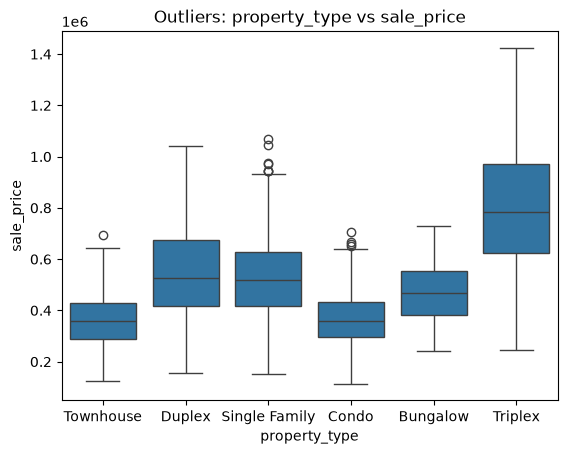

In [70]:
sns.boxplot(x='property_type', y='sale_price', data=house)
plt.title('Outliers: property_type vs sale_price')

plt.show()

## Analyis:
Here, sale_price is scaled in millions. This chart shows <br>
-	Triplex is the most expensive property with median price of $700,000, while some of the Triplex have price closer to $1.4 million. <br>

-	Duplex & Single Family houses share the similar median around $500,000. <br>

-	Townhouses & Condos represent the most affordable properties with median around $360,000.

#### There are no major outliers so skip the assumption of normality by relying on CLT.

count    6.000000e+00
mean     1.377000e+06
std      4.648871e+04
min      1.318000e+06
25%      1.343250e+06
50%      1.380000e+06
75%      1.416000e+06
max      1.425000e+06
Name: sale_price, dtype: float64

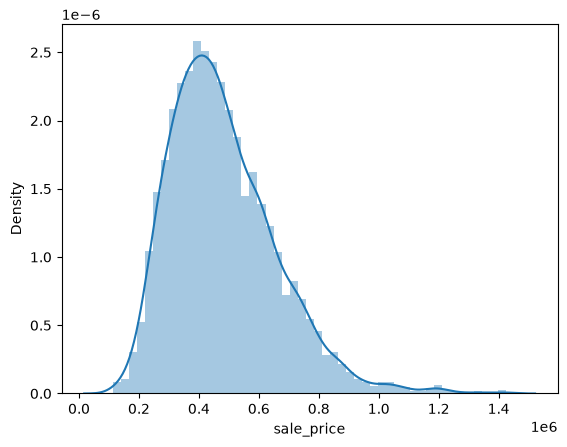

In [71]:
outlier_analysis_Tukey(house,'sale_price')

### Homegenity of Variances: 
- Levene's test is less sensitive to normality
- **H0: All the groups have equal variance**
- **H1: All the groups donot have equal variances**

In [72]:
levene(grp1,grp2,grp3,grp4,grp5,grp6)

LeveneResult(statistic=np.float64(132.952276783879), pvalue=np.float64(1.1492182153054111e-132))

### Since p-value=1.1492182153054111e-132<0.05 so reject H0: Variances are equal
### Conclude: Variances of all the groups are not equal

A general rule of thumb for equal variances is to compare the smallest and largest sample standard deviations. This is much like the rule of thumb for equal variances for the test for independent means. **If the ratio of these two sample standard deviations falls within 0.5 to 2**, then it may be that the assumption is not violated.

In [73]:
house.groupby('property_type').agg({'sale_price':'describe'})

sale_price                                                    \
                   count           mean            std       min       25%   
property_type                                                                
Bungalow           139.0  471460.431655  112865.654792  242000.0  382500.0   
Condo             1211.0  366817.506193   98985.902114  114000.0  295000.0   
Duplex             493.0  547251.521298  166776.021917  155000.0  418000.0   
Single Family     2254.0  524967.613132  150022.807314  153000.0  416250.0   
Townhouse          649.0  359906.009245   94998.239641  126000.0  287000.0   
Triplex            254.0  805787.401575  238171.148810  246000.0  622250.0   

                                              
                    50%       75%        max  
property_type                                 
Bungalow       466000.0  554000.0   728000.0  
Condo          358000.0  433000.0   704000.0  
Duplex         528000.0  673000.0  1042000.0  
Single Family  519000.0  626000.0  1067000.0  
Townhouse      358000.0  430000.0   695000.0  
Triplex        782000.0  972500.0  1425000.0

In [74]:
238171.148810/94998.239641


2.5071111813234954

### Here, the ratio of largest and smallest sample std is 2.5>2 so variance assumption is violated

### Applying Welch's anova

In [75]:
pg.welch_anova(dv='sale_price', between='property_type', data=house)

,Source,ddof1,ddof2,F,p_unc,np2
0,property_type,5,838.321523,526.797026,8.379405e-256,0.37383


### Here, p-value=8.379405e-256<0.05 so reject H0: the means of all the groups are equal
### Conclude: There is at-least one group with mean different from other groups

#### Apply Tukey HSD Post-Hoc-Test

In [76]:
pt = pg.pairwise_tukey(dv='sale_price', between='property_type', data=house)
print(pt)

                A              B         mean_A         mean_B           diff  \
0        Bungalow          Condo  471460.431655  366817.506193  104642.925461   
1        Bungalow         Duplex  471460.431655  547251.521298  -75791.089643   
2        Bungalow  Single Family  471460.431655  524967.613132  -53507.181478   
3        Bungalow      Townhouse  471460.431655  359906.009245  111554.422410   
4        Bungalow        Triplex  471460.431655  805787.401575 -334326.969920   
5           Condo         Duplex  366817.506193  547251.521298 -180434.015105   
6           Condo  Single Family  366817.506193  524967.613132 -158150.106939   
7           Condo      Townhouse  366817.506193  359906.009245    6911.496948   
8           Condo        Triplex  366817.506193  805787.401575 -438969.895382   
9          Duplex  Single Family  547251.521298  524967.613132   22283.908166   
10         Duplex      Townhouse  547251.521298  359906.009245  187345.512053   
11         Duplex        Tri

### p-value for each pair of groups is less than 0.05 so no two groups have equal means

### Kruskal-Wallis Test

The Kruskal-Wallis Test uses the following null and alternative hypotheses:

The null hypothesis (H0): The median is equal across all groups.

The alternative hypothesis: (Ha): The median is not equal across all groups.

In [77]:
kruskal(grp1,grp2,grp3,grp4,grp5,grp6)

KruskalResult(statistic=np.float64(1678.4143156666482), pvalue=np.float64(0.0))

### p-value=0.0<0.05 so reject H0:The median is equal across all groups.
### Conclude: The median is not equal across all groups.

# Feature engineering

### 'renovation_year' has 3408 values as 0, representting no information about renovation/no renovation
### map it to renovated: 'yes:1'/'no:0'

In [78]:
house['renovation_year'].value_counts()

renovation_year
0.0       3408
2021.0     105
2020.0     101
2016.0      90
2014.0      86
2012.0      85
2022.0      84
2019.0      83
2013.0      80
2005.0      77
2015.0      77
2018.0      75
2017.0      75
2007.0      75
2009.0      74
2011.0      71
2010.0      67
2023.0      65
2024.0      63
2008.0      61
2006.0      60
2025.0      38
Name: count, dtype: int64

In [79]:
house['renovated']=house['renovation_year'].apply(lambda x: 1 if x >0 else 0)
house.head()

,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqft,lot_size_sqft,year_built,renovation_year,garage,basement,sale_year,sale_price,renovated
0,Châteauguay,Centre-Ville,Townhouse,3,2,1160,2304.0,2022,0.0,Yes,No,2024,326000,0
1,Trois-Rivières,Cap-de-la-Madeleine,Duplex,4,4,1807,5869.0,2006,2024.0,No,Yes,2025,444000,1
2,Lévis,Charny,Townhouse,3,1,803,3387.0,1989,0.0,Yes,Yes,2025,273000,0
3,Laval,Fabreville,Single Family,3,3,1083,11417.0,1972,2016.0,Yes,Yes,2023,465000,1
4,Longueuil,Greenfield Park,Condo,2,2,714,5767.0,1997,2010.0,Yes,No,2022,371000,1


In [80]:
house=house.drop('renovation_year', axis=1)
house.head()

,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqft,lot_size_sqft,year_built,garage,basement,sale_year,sale_price,renovated
0,Châteauguay,Centre-Ville,Townhouse,3,2,1160,2304.0,2022,Yes,No,2024,326000,0
1,Trois-Rivières,Cap-de-la-Madeleine,Duplex,4,4,1807,5869.0,2006,No,Yes,2025,444000,1
2,Lévis,Charny,Townhouse,3,1,803,3387.0,1989,Yes,Yes,2025,273000,0
3,Laval,Fabreville,Single Family,3,3,1083,11417.0,1972,Yes,Yes,2023,465000,1
4,Longueuil,Greenfield Park,Condo,2,2,714,5767.0,1997,Yes,No,2022,371000,1


### Map 'garage': 0:No,1:Yes

In [81]:
house['garage']=house['garage'].apply(lambda x: 1 if x=='Yes' else 0)
house['garage'].value_counts(dropna=False)

garage
1    3476
0    1524
Name: count, dtype: int64

### Map 'basement': No:0,Yes:1

In [82]:
house['basement']=house['basement'].apply(lambda x: 1 if x=='Yes' else 0)
house['basement'].value_counts()

basement
1    3032
0    1968
Name: count, dtype: int64

### Map 'city' : East, West. North, South

### Divide cities into East, West, North, South of Qeubec based on their location
the division of these Quebec cities into geographic regions based on their location relative to Montreal and the St. Lawrence River corridor:
 #### West / SouthwestThese cities are in Western Quebec (Abitibi-Témiscamingue, Outaouais) or form the western portion of the Greater Montreal area.
 - Gatineau (Outaouais region)
 - Rouyn-Noranda (Abitibi-Témiscamingue)
 - Val-d'Or (Abitibi-Témiscamingue)
 - Vaudreuil-Dorion (Montérégie - West of Montreal)
 - Dollard-des-Ormeaux (West Island of Montreal)
 - Pointe-Claire (West Island of Montreal)
#### North / Laurentians & Lanaudière
These cities sit directly north of Montreal or across the Rivière des Prairies / Rivière des Mille Îles.
- Laval (Immediate north of Montreal)
- Terrebonne (Lanaudière)
- Repentigny (Lanaudière)
- Blainville (Laurentians)
- Mirabel (Laurentians)
- Saint-Jérôme (Laurentians)
####  South / South Shore & Eastern Townships
These cities are located south of the St. Lawrence River relative to Montreal, extending down to the US border.
- Longueuil (South Shore)
- Brossard (South Shore)
- Boucherville (South Shore)
- Saint-Bruno-de-Montarville (South Shore)
- Candiac (South Shore)
- Châteauguay (South Shore / Montérégie)
- Saint-Jean-sur-Richelieu (Montérégie)
- Granby (Montérégie / Cantons-de-l'Est)
- Sherbrooke (Eastern Townships)
  #### East / Eastern Quebec & St. Lawrence Corridor
  These cities are located further down the St. Lawrence River corridor or in northeastern Quebec.
- Québec (Capitale-Nationale)
- Lévis (Chaudière-Appalaches, directly across from Quebec City)
- Trois-Rivières (Mauricie - midway point east)
- Drummondville (Centre-du-Québec - east-central)
- Victoriaville (Centre-du-Québec - east-central)
- Saguenay (Saguenay–Lac-Saint-Jean)Alma (Saguenay–Lac-Saint-Jean)
- Rimouski (Bas-Saint-Laurent)
- Baie-Comeau (Côte-Nord)Sept-Îles (Côte-Nord)

In [83]:
house['city'].value_counts(normalize=True)

city
Montréal                      0.1838
Québec                        0.1058
Laval                         0.0920
Longueuil                     0.0788
Brossard                      0.0488
Sherbrooke                    0.0440
Gatineau                      0.0414
Terrebonne                    0.0348
Repentigny                    0.0294
Trois-Rivières                0.0274
Lévis                         0.0248
Saint-Jean-sur-Richelieu      0.0242
Saint-Jérôme                  0.0234
Blainville                    0.0224
Saguenay                      0.0186
Mirabel                       0.0180
Granby                        0.0180
Drummondville                 0.0178
Dollard-des-Ormeaux           0.0164
Châteauguay                   0.0162
Vaudreuil-Dorion              0.0158
Boucherville                  0.0144
Saint-Bruno-de-Montarville    0.0114
Victoriaville                 0.0112
Candiac                       0.0110
Pointe-Claire                 0.0102
Rimouski                      0.0

In [140]:
PWest=['Gatineau','Rouyn-Noranda',"Val-d'Or",'Vaudreuil-Dorion','Dollard-des-Ormeaux','Pointe-Claire']
PNorth=['Laval','Terrebonne','Repentigny','Blainville','Mirabel','Saint-Jérôme']
PSouth=['Longueuil','Brossard','Boucherville','St-Bruno-de-Montarville','Candiac','Châteauguay','Saint-Jean-sur-Richelieu',\
       'Granby','Sherbrooke']
PEast=['Québec','Lévis','Trois-Rivières','Drummondville','Victoriaville','Saguenay','Alma','Rimouski','Baie-Comeau','Sept-Îles']

In [142]:
# Build the mapping dictionary
city_map={}
for city in PWest: city_map[city]='PWest'
for city in PNorth: city_map[city]='PNorth'
for city in PSouth: city_map[city]='PSouth'
for city in PEast: city_map[city]='PEast'

# Map dictionary to create new column
house['ProvLocation']=house['city'].map(city_map)

house.head()

,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqft,lot_size_sqft,year_built,garage,basement,sale_year,sale_price,renovated,sqft_relative_to_neighborhood,years_newer_than_neighborhood,living_area_sqft_flag,lot_size_sqft_flag,ProvLocation
0,Châteauguay,Centre-Ville,Townhouse,3,2,1160,2304.0,2022,1,0,2024,326000,0,0.80,33.0,0,0,PSouth
1,Trois-Rivières,Cap-de-la-Madeleine,Duplex,4,4,1807,5869.0,2006,0,1,2025,444000,1,1.00,13.0,0,0,PEast
2,Lévis,Charny,Townhouse,3,1,803,3387.0,1989,1,1,2025,273000,0,0.99,-1.5,0,0,PEast
3,Laval,Fabreville,Single Family,3,3,1083,11417.0,1972,1,1,2023,465000,1,1.46,-7.0,0,0,PNorth
4,Longueuil,Greenfield Park,Condo,2,2,714,5767.0,1997,1,0,2022,371000,1,1.00,2.0,0,0,PSouth


In [143]:
house['ProvLocation'].value_counts()

ProvLocation
PSouth    1277
PEast     1171
PNorth    1100
PWest      476
Name: count, dtype: int64

### For each city, find the neighborhoods

In [144]:
for city in house['city'].value_counts().index.unique():
    print(city,"**************",house[house['city']==city]['neighborhood'].value_counts().index.unique(),sep="\n")
    print("*"*50)
    

Montréal
**************
Index(['Saint-Léonard', 'Outremont', 'Villeray', 'Verdun', 'LaSalle',
       'Mercier', 'Plateau-Mont-Royal', 'Ville-Marie', 'Ahuntsic', 'NDG',
       'Rosemont', 'Pointe-aux-Trembles', 'Lachine', 'Hochelaga-Maisonneuve'],
      dtype='object', name='neighborhood')
**************************************************
Québec
**************
Index(['Sillery', 'Lebourgneuf', 'Sainte-Foy', 'Charlesbourg', 'Beauport',
       'Vanier', 'Limoilou', 'Val-Bélair'],
      dtype='object', name='neighborhood')
**************************************************
Laval
**************
Index(['Sainte-Dorothée', 'Fabreville', 'Pont-Viau', 'Duvernay', 'Vimont',
       'Chomedey'],
      dtype='object', name='neighborhood')
**************************************************
Longueuil
**************
Index(['Greenfield Park', 'Vieux-Longueuil', 'Saint-Hubert',
       'Le Vieux-Longueuil'],
      dtype='object', name='neighborhood')
**************************************************
Bros

# Group by BOTH neighborhood AND property type to get an accurate baseline

In [89]:
# transform() calculates the median for the group, but repeats (broadcasts) that value for every single matching row.
neighborhood_medians=house.groupby(['neighborhood','property_type'])['lot_size_sqft'].transform('median')
neighborhood_medians

0       2889.5
1       5869.0
2       3410.0
3       7835.0
4       5767.0
         ...  
4995    7678.0
4996    8823.0
4997    4515.0
4998    6488.0
4999    5767.0
Name: lot_size_sqft, Length: 5000, dtype: float64

In [90]:
house['sqft_relative_to_neighborhood']=round(house['lot_size_sqft']/neighborhood_medians,2)
house.head()

,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqft,lot_size_sqft,year_built,garage,basement,sale_year,sale_price,renovated,sqft_relative_to_neighborhood
0,Châteauguay,Centre-Ville,Townhouse,3,2,1160,2304.0,2022,1,0,2024,326000,0,0.80
1,Trois-Rivières,Cap-de-la-Madeleine,Duplex,4,4,1807,5869.0,2006,0,1,2025,444000,1,1.00
2,Lévis,Charny,Townhouse,3,1,803,3387.0,1989,1,1,2025,273000,0,0.99
3,Laval,Fabreville,Single Family,3,3,1083,11417.0,1972,1,1,2023,465000,1,1.46
4,Longueuil,Greenfield Park,Condo,2,2,714,5767.0,1997,1,0,2022,371000,1,1.00


### A neighborhood that only has 1 or 2 homes of a specific type, their ratio will naturally land at or right next to 1.0
- Around 0.5 ratio means very compact, smaller units in that neighborhood
- Ratio 1.0 means standard, typical property for that group in that particular neighborhood
- Around 2.0 means largest/luxury houses

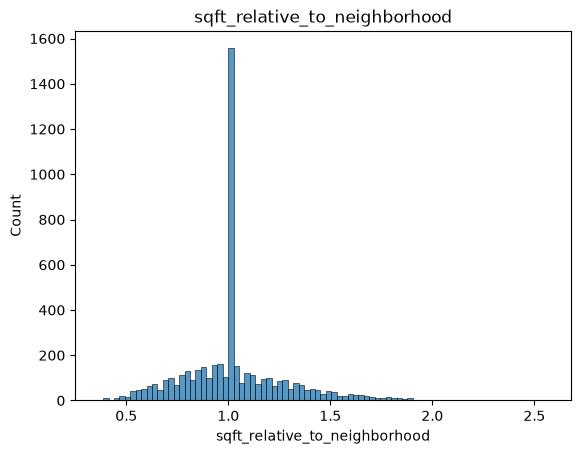

In [91]:
sns.histplot(x=house['sqft_relative_to_neighborhood'])
plt.title('sqft_relative_to_neighborhood')
plt.show()

In [92]:
#  Get the neighborhood baseline year
median_year=house.groupby(['city','neighborhood'])['year_built'].transform('median')
median_year

0       1989.0
1       1993.0
2       1990.5
3       1979.0
4       1995.0
         ...  
4995    1983.0
4996    1990.0
4997    1976.5
4998    1986.0
4999    1993.0
Name: year_built, Length: 5000, dtype: float64

In [93]:
#  Calculate how much newer or older the house is relative to its peers
house['years_newer_than_neighborhood'] = house['year_built'] - median_year
house.head()

,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqft,lot_size_sqft,year_built,garage,basement,sale_year,sale_price,renovated,sqft_relative_to_neighborhood,years_newer_than_neighborhood
0,Châteauguay,Centre-Ville,Townhouse,3,2,1160,2304.0,2022,1,0,2024,326000,0,0.80,33.0
1,Trois-Rivières,Cap-de-la-Madeleine,Duplex,4,4,1807,5869.0,2006,0,1,2025,444000,1,1.00,13.0
2,Lévis,Charny,Townhouse,3,1,803,3387.0,1989,1,1,2025,273000,0,0.99,-1.5
3,Laval,Fabreville,Single Family,3,3,1083,11417.0,1972,1,1,2023,465000,1,1.46,-7.0
4,Longueuil,Greenfield Park,Condo,2,2,714,5767.0,1997,1,0,2022,371000,1,1.00,2.0


### Capping the outliers

In [94]:
house2=house.copy()

In [95]:
#the following UDF is for assigning 1 to outlires and 0 otherwise
#we want to add a new feature that has a value of 1  if that record is outliers  based on that feature
# i will add new column with the same value then I use this function to change its value to 0 and 1
def colunm_outliers(df_train,col):#col is name of column that you want to fix its outliers
    i=0 # i is number of outliers that they are less than lower outer fence(Q1-3*IQR)
    j=0 # j is  number of outliers that they are bigger than upper outer fence(Q3+3*IQR)
    Q1=df_train[col].quantile(0.25) # finding 1st quartile(lowe quartile)
    Q3=df_train[col].quantile(0.75) # finding 3rd quartile(upper quartile)
    IQR=Q3-Q1 #calculationg Inter Quartile Range
    UOF=Q3+3*(IQR)#UOF=upper outer fence
    LOF=Q1-3*(IQR)#LOF=lower outer fence
    flag_col=[] # Create a list to assign value( this is a new feature that we will add to specify if that record is outliers or not based on that feature )
    for val in df_train[col]:#val is value of that column . here we select values of that column one by one and execute the loop
        if val<LOF:   
            flag_col.append(1)# if value is less than LOF we will repalce that with 1
            i+=1
        elif val>UOF :  # if value is bigger than UOF we will repalce that with 1 
            flag_col.append(1)# if value is less than LOF we will repalce that with 1
            j+=1
        else : flag_col.append(0)
    df_train[col + "_flag"]=flag_col # update the column by assigning Clean_col
    sns.countplot(x=df_train[col + "_flag"])#Plotting univariate distributions
    plt.show()
    print(f'Number of outliers that they are less than lower outer fence({LOF}): ',i,f'\nNumber of outliers that they are greater than upper outer fence ({UOF}) : ',j)
    return df_train[col + "_flag"] .value_counts()

In [100]:
#I want to replace values bigger than upper outer fence with upper outer fence and values less than lower outer fence with
#lower outer fence
#lower outer fence: Q1 - 3*IQR
#upper outer fence: Q3 + 3*IQR
def fixing_outliers(df_train,col):#col is name of column that you want to fix its outliers
    i=0 # i is number of outliers that they are less than lower outer fence
    j=0 # j is  number of outliers that they are bigger than upper outer fence
    Q1=df_train[col].quantile(0.25) # finding 1st quartile(lowe quartile)
    Q3=df_train[col].quantile(0.75) # finding 3rd quartile(upper quartile)
    IQR=Q3-Q1 #calculationg Inter Quartile Range
    UOF1=Q3+3*(IQR)#UOF=upper outer fence
    LOF1=Q1-3*(IQR)#LOF=lower outer fence
    Clean_col=[] # Create an ematy list to append value to it
    for val in df_train[col]:#val is value of that column . here we select values of that column one by one and execute the loop
        if val<LOF1:   
            Clean_col.append(LOF1)# if value is less than LOF we will repalce that with LOF
            i+=1
        elif val>UOF1 :  # if value is bigger than UOF we will repalce that with UOF 
            Clean_col.append(UOF1)
            j+=1
        else : Clean_col.append(val)
    df_train[col]=Clean_col # update the column by assigning Clean_col
    sns.distplot(df_train[col])#Plotting univariate distributions
    plt.show()
    print(f'Number of outliers that they are less than lower outer fence({LOF1}): ',i,f'\nNumber of outliers that they are bigger than upper outer fence ({UOF1}) : ',j)
    return df_train[col] .describe()

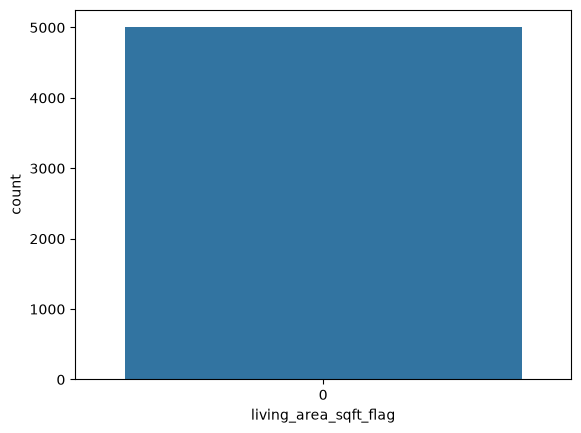

Number of outliers that they are less than lower outer fence(-1290.0):  0 
Number of outliers that they are greater than upper outer fence (3855.0) :  0


living_area_sqft_flag
0    5000
Name: count, dtype: int64

In [101]:
colunm_outliers(house,'living_area_sqft')

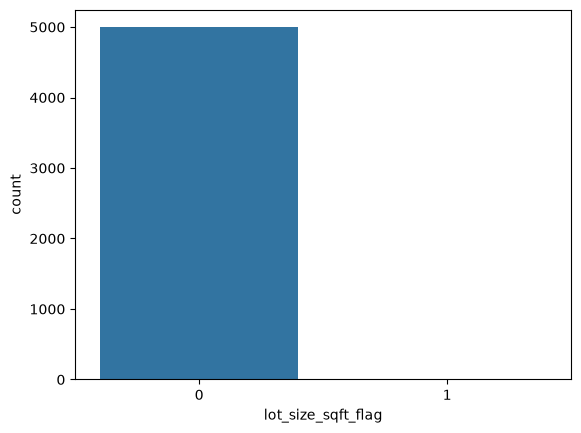

Number of outliers that they are less than lower outer fence(-2776.0):  0 
Number of outliers that they are greater than upper outer fence (14500.0) :  7


lot_size_sqft_flag
0    4993
1       7
Name: count, dtype: int64

In [102]:
colunm_outliers(house,'lot_size_sqft')

## Analysis: 
These outliers are capped such as the values that are lower than the lower fence -2,776sqft are capped to the lower fence and the values greater than the upper fence 14,500sqft are capped to the upper fence.

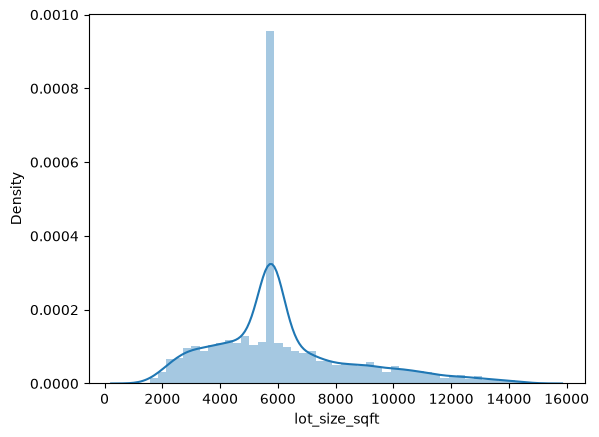

Number of outliers that they are less than lower outer fence(-2776.0):  0 
Number of outliers that they are bigger than upper outer fence (14500.0) :  7


count     5000.00000
mean      6138.12360
std       2455.22636
min       1570.00000
25%       4628.00000
50%       5767.00000
75%       7096.00000
max      14500.00000
Name: lot_size_sqft, dtype: float64

In [103]:
fixing_outliers(house,'lot_size_sqft')

## Analysis:
The density plot below shows that outliers are successfully capped to the relative fences. Now the distribution is smooth without long tails.

### Handling Missing Values(CONT.)

In [104]:
percentage_of_miss(house)

,Number of Missing,Percentage of Miss


In [105]:


# -------------------------------
# 1) Auto-infer column types
# -------------------------------
def split_cols(df: pd.DataFrame):
    num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
    return num_cols, cat_cols

# Choose a numeric subset for MICE (e.g., those with missingness)
#  it won't process more than 30 columns at once.
def choose_mice_numeric_cols(df: pd.DataFrame, max_cols: int = 30):
    num_cols, _ = split_cols(df) # underscore _ to discard the categorical columns
                                #because MICE algorithms typically handle numeric data
    # sort numeric columns by missing rate descending; pick top up to max_cols
    miss_rates = df[num_cols].isna().mean().sort_values(ascending=False)
    mice_cols = [c for c in miss_rates.index if miss_rates[c] > 0][:max_cols]
    other_num = [c for c in num_cols if c not in mice_cols]
    return mice_cols, other_num

# -------------------------------
# 2) Build scalable preprocessors
# -------------------------------
def build_pipeline(X_train: pd.DataFrame,
                   mice_max_cols: int = 30,
                   n_nearest_features: int = 20):
    mice_num_cols, other_num_cols = choose_mice_numeric_cols(X_train, mice_max_cols)
    _, cat_cols = split_cols(X_train)

    # (a) MICE on selected numeric columns only
    mice_block = Pipeline([
        ('imp_mice', IterativeImputer(
            random_state=42,
            max_iter=10, #Sets a maximum of 10 imputation cycles/rounds to find a stable value before stopping.
            initial_strategy='median', # Fills any missing gaps with the median value as a placeholder during the very first pass
            n_nearest_features=min(n_nearest_features, max(1, len(mice_num_cols))),
            sample_posterior=False,
            tol=1e-3
        ))
    ])

    # (b) Simple median for the rest of numeric columns
    other_num_block = Pipeline([
        ('imp_med', SimpleImputer(strategy='median'))
    ])

    # (c) Categorical imputation (robust + cheap)
    # Use "Unknown" (or most_frequent). No OHE here since we’re returning imputed features, not modeling.
    cat_block = Pipeline([
        ('imp_cat', SimpleImputer(strategy='constant', fill_value='Unknown'))
    ])

    pre = ColumnTransformer(
        transformers=[
            ('mice_num', mice_block, mice_num_cols),
            ('med_num', other_num_block, other_num_cols),
            ('cat',      cat_block,   cat_cols),
        ],
        remainder='passthrough'
    ).set_output(transform='pandas')

    return pre, {'mice_num': mice_num_cols, 'med_num': other_num_cols, 'cat': cat_cols}



In [106]:
# Separate features and target
X_train = house.drop(columns=['sale_price'])  # everything except target
y_train = house['sale_price'] 

In [107]:
percentage_of_miss(X_train)

,Number of Missing,Percentage of Miss


In [110]:
# -------------------------------
# 3) Fit on TRAIN, reuse for FUTURE
# -------------------------------
pre, cols = build_pipeline(X_train, mice_max_cols=30, n_nearest_features=20)
pre.fit(X_train)
X_train_imputed = pre.transform(X_train)
joblib.dump(pre, 'imputer_hybrid.joblib')

['imputer_hybrid.joblib']

In [111]:
percentage_of_miss(X_train_imputed)

,Number of Missing,Percentage of Miss


In [112]:
X_train=X_train_imputed.copy()

In [113]:
X_train.head(2)

,med_num__bedrooms,med_num__bathrooms,med_num__living_area_sqft,med_num__lot_size_sqft,med_num__year_built,med_num__garage,med_num__basement,med_num__sale_year,med_num__renovated,med_num__sqft_relative_to_neighborhood,med_num__years_newer_than_neighborhood,med_num__living_area_sqft_flag,med_num__lot_size_sqft_flag,cat__city,cat__neighborhood,cat__property_type
0,3.0,2.0,1160.0,2304.0,2022.0,1.0,0.0,2024.0,0.0,0.8,33.0,0.0,0.0,Châteauguay,Centre-Ville,Townhouse
1,4.0,4.0,1807.0,5869.0,2006.0,0.0,1.0,2025.0,1.0,1.0,13.0,0.0,0.0,Trois-Rivières,Cap-de-la-Madeleine,Duplex


In [114]:
X_train.columns

Index(['med_num__bedrooms', 'med_num__bathrooms', 'med_num__living_area_sqft',
       'med_num__lot_size_sqft', 'med_num__year_built', 'med_num__garage',
       'med_num__basement', 'med_num__sale_year', 'med_num__renovated',
       'med_num__sqft_relative_to_neighborhood',
       'med_num__years_newer_than_neighborhood',
       'med_num__living_area_sqft_flag', 'med_num__lot_size_sqft_flag',
       'cat__city', 'cat__neighborhood', 'cat__property_type'],
      dtype='object')

In [115]:
def strip_prefixes(df: pd.DataFrame) -> pd.DataFrame:
    """Remove the ColumnTransformer prefixes like 'mice_num__' or 'cat__'."""
    df = df.copy()
    df.columns = [re.sub(r'.*?__', '', c) for c in df.columns]
    """
    re.sub(pattern, replacement, text)
    replaces any part of text matching pattern with replacement.
    
    Pattern explanation:
    
    .*? → “any character (.) repeated zero or more times (*), but as few as possible (?)”.
    This lazily captures everything at the start of the string, regardless of underscores.
    
    __ → the double underscore itself.
    
    Together, .*?__ means:
    “Match everything from the start of the string up to and including the first occurrence of a double underscore.”
    
    Replacement is an empty string '',
    so the matched prefix (for example mice_num__ or cat__) is removed.
    """
    return df

In [116]:
X_train= strip_prefixes(X_train)

In [117]:
X_train.columns

Index(['bedrooms', 'bathrooms', 'living_area_sqft', 'lot_size_sqft',
       'year_built', 'garage', 'basement', 'sale_year', 'renovated',
       'sqft_relative_to_neighborhood', 'years_newer_than_neighborhood',
       'living_area_sqft_flag', 'lot_size_sqft_flag', 'city', 'neighborhood',
       'property_type'],
      dtype='object')

In [118]:
# For DT, Randome Forest, and Extra Trees

def handle_missing_for_dt(df):
    df = df.copy()

    for col in df.columns:

        # only create missing indicator if column has missing values
        if df[col].isna().any():
            df[col + "_missing"] = df[col].isna().astype(int)

        # numeric columns
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(9999999)

        # categorical/text columns
        else:
            df[col] = df[col].fillna("UnKnown")

    return df

### Separate features and target

In [119]:
house_copy=house.copy()

In [121]:
X=house.drop(columns='sale_price') # all the columns except target
y=house['sale_price']

### Split into Train and Test

In [122]:
# Split into train and test sets FIRST to avoid data leakage
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Initialize the Target Encoder 

In [126]:
# smoothing  handle rare categories (like a small town with only 1 or 2 rows of data)
encoder = ce.TargetEncoder(cols=["city", "neighborhood"], smoothing=10.0)

### Fit on training data nad transform on train and test data

In [127]:
X_train.columns

Index(['city', 'neighborhood', 'property_type', 'bedrooms', 'bathrooms',
       'living_area_sqft', 'lot_size_sqft', 'year_built', 'garage', 'basement',
       'sale_year', 'renovated', 'sqft_relative_to_neighborhood',
       'years_newer_than_neighborhood', 'living_area_sqft_flag',
       'lot_size_sqft_flag'],
      dtype='object')

In [130]:
X_train = encoder.fit_transform(X_train, y_train)
X_test=encoder.transform(X_test)

In [132]:
X_test

,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqft,lot_size_sqft,year_built,garage,basement,sale_year,renovated,sqft_relative_to_neighborhood,years_newer_than_neighborhood,living_area_sqft_flag,lot_size_sqft_flag
1501,388118.518519,399806.653547,Townhouse,2,3,1230,2609.0,1993,1,1,2023,0,0.95,25.0,0,0
2586,332374.439349,419565.040650,Single Family,2,3,1510,6949.0,1988,1,1,2021,1,0.94,5.0,0,0
2653,388118.518519,370454.763086,Condo,2,1,589,5767.0,1955,0,0,2025,0,1.00,-17.0,0,0
1055,541683.672101,524448.966923,Bungalow,3,1,973,6539.0,1988,1,1,2025,1,1.00,-1.5,0,0
705,576133.152174,568770.908733,Condo,3,2,799,5767.0,1973,1,0,2024,0,1.00,-22.0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4711,409339.201249,432046.461434,Townhouse,4,2,1002,2344.0,2017,1,1,2022,0,0.84,30.0,0,0
2313,576133.152174,573981.881154,Single Family,4,2,972,8433.0,1980,1,1,2024,0,1.14,-13.0,0,0
3214,469537.472787,419565.040650,Condo,2,2,910,5767.0,1988,0,0,2024,0,1.00,-5.0,0,0
2732,388118.518519,399806.653547,Triplex,6,6,2608,3200.0,2017,1,1,2022,0,0.73,49.0,0,0


In [133]:
categorical_cols=X_train.select_dtypes(include='object').columns
encoder = OneHotEncoder(handle_unknown='ignore', #drop='first', 
                        #sparse=False
                       sparse_output=False #sparse was removed and replaced with:sparse_output
                       )

'''
drop='first' → avoids dummy variable trap

handle_unknown='ignore' → prevents crash on new categories in test data

sparse=False → returns DataFrame-friendly output
'''

#FIT on TRAIN ONLY (no data leakage)
encoder.fit(X_train[categorical_cols])

#Transform Train & Test
X_train_encoded = encoder.transform(X_train[categorical_cols])
X_test_encoded  = encoder.transform(X_test[categorical_cols])

#Convert back to DataFrame with proper column names
encoded_cols = encoder.get_feature_names_out(categorical_cols)

X_train_encoded_df = pd.DataFrame(X_train_encoded, columns=encoded_cols, index=X_train.index)
X_test_encoded_df  = pd.DataFrame(X_test_encoded,  columns=encoded_cols, index=X_test.index)

# Drop original categorical columns & attach encoded ones
X_train_2 = X_train.drop(columns=categorical_cols)
X_test_2  = X_test.drop(columns=categorical_cols)

X_train_encoded = pd.concat([X_train_2, X_train_encoded_df], axis=1)
X_test_encoded  = pd.concat([X_test_2, X_test_encoded_df], axis=1)

In [135]:
X_train_encoded.head()

,city,neighborhood,bedrooms,bathrooms,living_area_sqft,lot_size_sqft,year_built,garage,basement,sale_year,renovated,sqft_relative_to_neighborhood,years_newer_than_neighborhood,living_area_sqft_flag,lot_size_sqft_flag,property_type_Bungalow,property_type_Condo,property_type_Duplex,property_type_Single Family,property_type_Townhouse,property_type_Triplex
4227,516047.325585,520185.229623,4,3,1815,4832.0,1978,0,1,2025,0,0.62,-1.0,0,0,0.0,0.0,0.0,1.0,0.0,0.0
4676,576133.152174,556278.176845,4,3,1287,5808.0,1958,1,1,2025,1,0.83,-32.0,0,0,0.0,0.0,0.0,1.0,0.0,0.0
800,324754.625000,324754.625000,3,1,1161,3321.0,1973,1,1,2025,0,1.00,-15.0,0,0,0.0,0.0,0.0,0.0,1.0,0.0
3671,609283.911672,613124.445470,3,3,1550,11492.0,2019,1,1,2024,0,1.46,24.0,0,0,0.0,0.0,0.0,1.0,0.0,0.0
4193,578184.064318,554112.761214,4,2,1237,5236.0,1956,1,1,2024,0,0.73,-43.5,0,0,0.0,0.0,0.0,1.0,0.0,0.0


In [136]:
X_train_encoded.columns

Index(['city', 'neighborhood', 'bedrooms', 'bathrooms', 'living_area_sqft',
       'lot_size_sqft', 'year_built', 'garage', 'basement', 'sale_year',
       'renovated', 'sqft_relative_to_neighborhood',
       'years_newer_than_neighborhood', 'living_area_sqft_flag',
       'lot_size_sqft_flag', 'property_type_Bungalow', 'property_type_Condo',
       'property_type_Duplex', 'property_type_Single Family',
       'property_type_Townhouse', 'property_type_Triplex'],
      dtype='object')

### Scaling

In [138]:
robust=RobustScaler()
X_train_scaled=robust.fit_transform(X_train_encoded)
X_test_scaled=robust.transform(X_test_encoded)
train_robust=pd.DataFrame(X_train_scaled,columns=X_train_encoded.columns)
test_robust=pd.DataFrame(X_test_scaled,columns=X_test_encoded.columns)
train_robust.head()

,city,neighborhood,bedrooms,bathrooms,living_area_sqft,lot_size_sqft,year_built,garage,basement,sale_year,renovated,sqft_relative_to_neighborhood,years_newer_than_neighborhood,living_area_sqft_flag,lot_size_sqft_flag,property_type_Bungalow,property_type_Condo,property_type_Duplex,property_type_Single Family,property_type_Townhouse,property_type_Triplex
0,-0.055613,0.129220,0.5,1.0,0.724080,-0.378811,-0.184211,-1.0,0.0,0.333333,0.0,-1.652174,-0.027027,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.263967,0.380183,0.5,1.0,0.010807,0.016611,-0.710526,0.0,0.0,0.333333,1.0,-0.739130,-0.864865,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,-1.073048,-1.229657,0.0,-1.0,-0.159406,-0.990986,-0.315789,0.0,0.0,0.333333,0.0,0.000000,-0.405405,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.440287,0.775449,0.0,1.0,0.366093,2.319457,0.894737,0.0,0.0,0.000000,0.0,2.000000,0.648649,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.274876,0.365126,0.5,0.0,-0.056738,-0.215132,-0.763158,0.0,0.0,0.000000,0.0,-1.173913,-1.175676,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
